In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#解决中文乱码
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

#读取霸王茶姬、奈雪csv
df_cha = pd.read_csv("cha_data_original.csv",encoding="gbk")
df_naixue = pd.read_csv("naixue_data_original.csv",encoding="gbk")
num_cols = ["total_revenue","gross_profit","net_profit","gmv","store_total","store_franchise","avg_store_gmv"]
for col in num_cols:
    df_cha[col] = pd.to_numeric(df_cha[col],errors="coerce")
#查看原始数据
print("====霸王茶姬原始数据预览====")
print(df_cha.head())
print("\n原始数据形状：",df_cha.shape)

====霸王茶姬原始数据预览====
    period  total_revenue  gross_profit  net_profit    gmv  store_total  \
0  2024-03          27.80          8.92        5.15   68.2         5210   
1  2024-06          30.10          9.81        5.82   72.5         5850   
2  2024-09          32.50         10.23        6.21   76.8         6120   
3  2024-12         124.05         38.58       25.15  295.0         6440   
4  2025-03          33.93         16.45        6.50   87.0         6920   

   store_direct  store_franchise  avg_store_gmv  
0         158.0           5052.0           48.5  
1         172.0           5678.0           49.2  
2         185.0           5935.0           50.1  
3         193.0           6247.0           51.2  
4           NaN              NaN           45.6  

原始数据形状： (9, 9)


In [35]:
df_cha = df_cha.copy()

#1、统计每一列有多少缺失值
print("====缺失值统计====")
print(df_cha.isnull().sum())

#2、删除【营收、GMV、门店总数】三者全部为空的无效行；局部字段缺失保留，不强行补数
df_cha = df_cha.dropna(subset=["total_revenue","gmv","store_total"],how="all")

#3、业务逻辑校验：财务数字不能负数；门店不能小于0
df_cha = df_cha[df_cha["total_revenue"] >= 0]
df_cha = df_cha[df_cha["store_total"] >= 0]

print("\n清洗完成之后样本数量：", len(df_cha))
print(df_cha.head())

====缺失值统计====
period             0
total_revenue      0
gross_profit       0
net_profit         0
gmv                0
store_total        0
store_direct       5
store_franchise    5
avg_store_gmv      1
dtype: int64

清洗完成之后样本数量： 9
    period  total_revenue  gross_profit  net_profit    gmv  store_total  \
0  2024-03          27.80          8.92        5.15   68.2         5210   
1  2024-06          30.10          9.81        5.82   72.5         5850   
2  2024-09          32.50         10.23        6.21   76.8         6120   
3  2024-12         124.05         38.58       25.15  295.0         6440   
4  2025-03          33.93         16.45        6.50   87.0         6920   

   store_direct  store_franchise  avg_store_gmv  
0         158.0           5052.0           48.5  
1         172.0           5678.0           49.2  
2         185.0           5935.0           50.1  
3         193.0           6247.0           51.2  
4           NaN              NaN           45.6  


In [36]:
#衍生指标计算
import pandas as pd
import numpy as np

df_cha = df_cha.copy()

# np.where + np.divide 安全除法，遇到空值自动输出NaN，不会抛错
df_cha["gross_margin"] = np.divide(df_cha["gross_profit"], df_cha["total_revenue"], out=np.full(len(df_cha), np.nan), where=df_cha["total_revenue"]!=0)
df_cha["net_margin"] = np.divide(df_cha["net_profit"], df_cha["total_revenue"], out=np.full(len(df_cha), np.nan), where=df_cha["total_revenue"]!=0)
df_cha["franchise_ratio"] = np.divide(df_cha["store_franchise"], df_cha["store_total"], out=np.full(len(df_cha), np.nan), where=df_cha["store_total"]!=0)
df_cha["rev_gmv_ratio"] = np.divide(df_cha["total_revenue"], df_cha["gmv"], out=np.full(len(df_cha), np.nan), where=df_cha["gmv"]!=0)

#门店环比增速
df_cha["store_growth_qoq"] = df_cha["store_total"].pct_change()

#打印衍生指标预览，修复换行截断bug
print("====衍生经营财务指标====")
show_cols = ["period","gross_margin","net_margin","franchise_ratio","rev_gmv_ratio","store_growth_qoq"]
print(df_cha[show_cols])

====衍生经营财务指标====
    period  gross_margin  net_margin  franchise_ratio  rev_gmv_ratio  \
0  2024-03      0.320863    0.185252         0.969674       0.407625   
1  2024-06      0.325914    0.193355         0.970598       0.415172   
2  2024-09      0.314769    0.191077         0.969771       0.423177   
3  2024-12      0.311004    0.202741         0.970031       0.420508   
4  2025-03      0.484822    0.191571              NaN       0.390000   
5  2025-06      0.497515    0.178895              NaN       0.383520   
6  2025-09      0.508567    0.167904              NaN       0.378595   
7  2025-12      0.458433    0.090726              NaN       0.408708   
8  2026-03      0.415680    0.126904              NaN       0.447840   

   store_growth_qoq  
0               NaN  
1          0.122841  
2          0.046154  
3          0.052288  
4          0.074534  
5          0.033237  
6          0.006993  
7          0.001389  
8          0.044521  


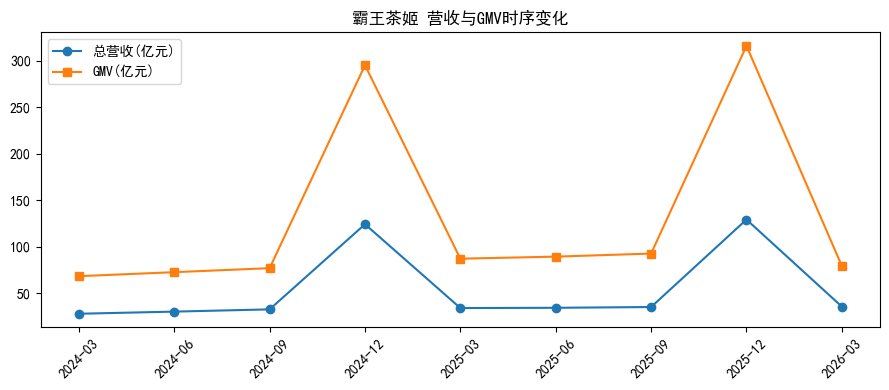

In [37]:
plt.figure(figsize=(9,4))
plt.plot(df_cha["period"],df_cha["total_revenue"],marker="o",label="总营收(亿元)")
plt.plot(df_cha["period"],df_cha["gmv"],marker="s",label="GMV(亿元)")
plt.title("霸王茶姬 营收与GMV时序变化")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("rev_gmv_trend.png")
plt.show()

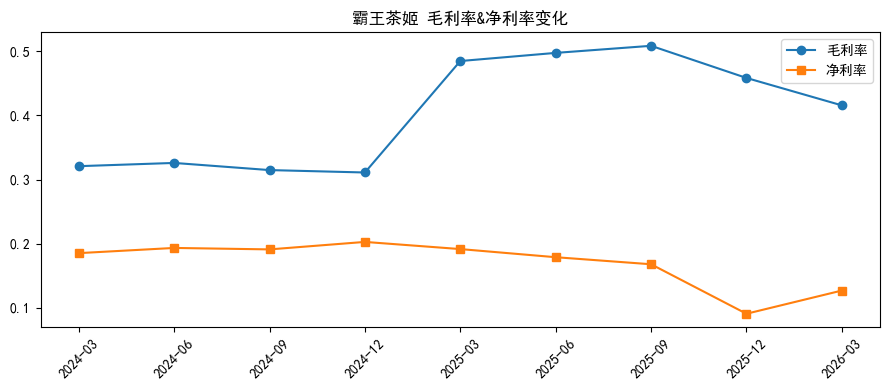

In [38]:
plt.figure(figsize=(9,4))
plt.plot(df_cha["period"],df_cha["gross_margin"],marker="o",label="毛利率")
plt.plot(df_cha["period"],df_cha["net_margin"],marker="s",label="净利率")
plt.title("霸王茶姬 毛利率&净利率变化")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("profit_margin_trend.png")
plt.show()

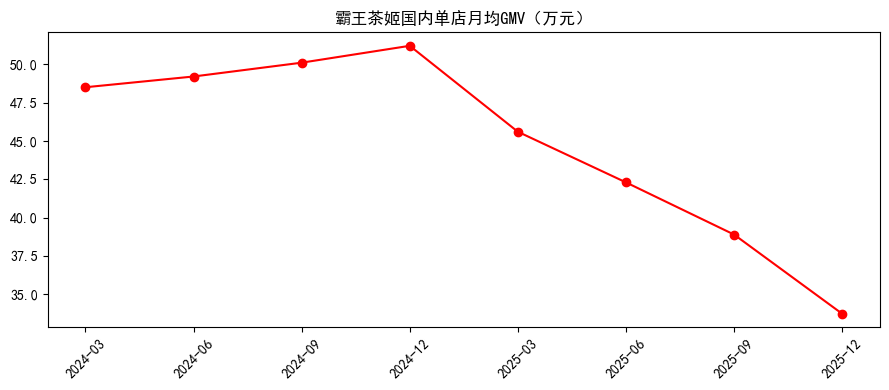

In [39]:
plt.figure(figsize=(9,4))
plt.plot(df_cha["period"],df_cha["avg_store_gmv"],marker="o",color="red")
plt.title("霸王茶姬国内单店月均GMV（万元）")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("avg_store_gmv_trend.png")
plt.show()

In [40]:
print("霸王茶姬全部列：",df_cha.columns.tolist())
print("奈雪全部列：",df_naixue.columns.tolist())

霸王茶姬全部列： ['period', 'total_revenue', 'gross_profit', 'net_profit', 'gmv', 'store_total', 'store_direct', 'store_franchise', 'avg_store_gmv', 'gross_margin', 'net_margin', 'franchise_ratio', 'rev_gmv_ratio', 'store_growth_qoq']
奈雪全部列： ['period', 'total_revenue', 'gross_profit', 'net_profit', 'gmv', 'store_total', 'avg_store_gmv']


#项目业务分析结论
1. 增长特征：2024年公司GMV、营收高速扩张；进入2025年后GMV增速显著放缓，出现“增收不增利”现象。
2. 盈利变化：净利率从2024年20%左右，出现明显下行，单店GMV持续下滑是压制利润的重要因素。
3. 商业模式：以加盟门店为主，GMV显著高于企业账面营收，营收‑GMV转化率体现加盟供货模式变现能力。
4. 对标对比：对比奈雪的茶（直营占比更高），两者盈利压力来源不同；霸王茶姬来自单店产出下滑，奈雪来自直营门店高昂运营成本。
5. 局限：部分季度披露数据不全，存在字段缺失，数据来源全部来自上市公司公开财报公告。

In [41]:
import pandas as pd
import numpy as np

# 1.读取原始备份数据
df_cha_raw = pd.read_csv("cha_data_original.csv")
df_naixue_raw = pd.read_csv("naixue_data_original.csv")

# 区分：流量指标（要扣减算Q4），时点指标（门店数、单店gmv不处理）
flow_cols = ["total_revenue","gross_profit","net_profit","gmv"]
point_cols_cha = ["period","store_total","store_direct","store_franchise","avg_store_gmv"]
point_cols_naixue = ["period","store_total","avg_store_gmv"]

# ==========处理霸王茶姬============
df_cha = df_cha_raw.copy()

# 取出2024 Q1/Q2/Q3/全年行
q1_24 = df_cha[df_cha["period"]=="2024-03"][flow_cols].iloc[0]
q2_24 = df_cha[df_cha["period"]=="2024-06"][flow_cols].iloc[0]
q3_24 = df_cha[df_cha["period"]=="2024-09"][flow_cols].iloc[0]
fy24 = df_cha[df_cha["period"]=="2024-12"][flow_cols].iloc[0]

# 计算2024 Q4单季度流量指标
q4_24 = fy24 - q1_24 - q2_24 - q3_24

# 取出2024‑12这一行的时点数据（门店等）
row_fy24 = df_cha[df_cha["period"]=="2024-12"].iloc[0].copy()
# 把算好的Q4流量填回去
row_fy24[flow_cols] = q4_24
# 修改period标记为2024‑12(Q4单季)，方便识别
row_fy24["period"] = "2024‑12(Q4)"

# ----2025 Q4计算----
q1_25 = df_cha[df_cha["period"]=="2025-03"][flow_cols].iloc[0]
q2_25 = df_cha[df_cha["period"]=="2025-06"][flow_cols].iloc[0]
q3_25 = df_cha[df_cha["period"]=="2025-09"][flow_cols].iloc[0]
fy25 = df_cha[df_cha["period"]=="2025-12"][flow_cols].iloc[0]
q4_25 = fy25 - q1_25 - q2_25 - q3_25

row_fy25 = df_cha[df_cha["period"]=="2025-12"].iloc[0].copy()
row_fy25[flow_cols] = q4_25
row_fy25["period"] = "2025‑12(Q4)"

# 构建清洗后的完整季度表：删掉原来的累计12月行，插入计算后的Q4行
df_cha_clean = df_cha[~df_cha["period"].isin(["2024-12","2025-12"])].copy()
df_cha_clean = pd.concat([df_cha_clean, pd.DataFrame([row_fy24, row_fy25])], ignore_index=True)

# 按时间顺序排序
time_order = ["2024-03","2024-06","2024-09","2024‑12(Q4)",
              "2025-03","2025-06","2025-09","2025‑12(Q4)","2026-03"]
df_cha_clean["period"] = pd.Categorical(df_cha_clean["period"], categories=time_order, ordered=True)
df_cha_clean = df_cha_clean.sort_values("period").reset_index(drop=True)

# =========处理奈雪的茶，完全相同逻辑=========
df_naixue = df_naixue_raw.copy()

q1_24_nx = df_naixue[df_naixue["period"]=="2024-03"][flow_cols].iloc[0]
q2_24_nx = df_naixue[df_naixue["period"]=="2024-06"][flow_cols].iloc[0]
q3_24_nx = df_naixue[df_naixue["period"]=="2024-09"][flow_cols].iloc[0]
fy24_nx = df_naixue[df_naixue["period"]=="2024-12"][flow_cols].iloc[0]
q4_24_nx = fy24_nx - q1_24_nx - q2_24_nx - q3_24_nx

row_fy24_nx = df_naixue[df_naixue["period"]=="2024-12"].iloc[0].copy()
row_fy24_nx[flow_cols] = q4_24_nx
row_fy24_nx["period"] = "2024‑12(Q4)"

q1_25_nx = df_naixue[df_naixue["period"]=="2025-03"][flow_cols].iloc[0]
q2_25_nx = df_naixue[df_naixue["period"]=="2025-06"][flow_cols].iloc[0]
q3_25_nx = df_naixue[df_naixue["period"]=="2025-09"][flow_cols].iloc[0]
fy25_nx = df_naixue[df_naixue["period"]=="2025-12"][flow_cols].iloc[0]
q4_25_nx = fy25_nx - q1_25_nx - q2_25_nx - q3_25_nx

row_fy25_nx = df_naixue[df_naixue["period"]=="2025-12"].iloc[0].copy()
row_fy25_nx[flow_cols] = q4_25_nx
row_fy25_nx["period"] = "2025‑12(Q4)"

df_naixue_clean = df_naixue[~df_naixue["period"].isin(["2024-12","2025-12"])].copy()
df_naixue_clean = pd.concat([df_naixue_clean, pd.DataFrame([row_fy24_nx, row_fy25_nx])], ignore_index=True)

time_order_nx = ["2024-03","2024-06","2024‑12(Q4)","2025-03","2025-06","2025-09","2025‑12(Q4)","2026-03"]
df_naixue_clean["period"] = pd.Categorical(df_naixue_clean["period"], categories=time_order_nx, ordered=True)
df_naixue_clean = df_naixue_clean.sort_values("period").reset_index(drop=True)

# 输出清洗后的数据文件，保存到finance_milktea文件夹
df_cha_clean.to_csv("cha_data_processed.csv", index=False)
df_naixue_clean.to_csv("naixue_data_processed.csv", index=False)

# 打印查看结果，确认Q4数值合理，不再出现几百亿的异常大数字
print("霸王茶姬清洗后季度数据：")
display(df_cha_clean)
print("奈雪清洗后季度数据：")
display(df_naixue_clean)


霸王茶姬清洗后季度数据：


,period,total_revenue,gross_profit,net_profit,gmv,store_total,store_direct,store_franchise,avg_store_gmv
0,2024-03,27.80,8.92,5.15,68.20,5210,158.0,5052,48.50
1,2024-06,30.10,9.81,5.82,72.50,5850,172.0,5678,49.20
2,2024-09,32.50,10.23,6.21,76.80,6120,185.0,5935,50.10
3,2024‑12(Q4),33.65,9.62,7.97,77.50,6440,193.0,6247,51.20
4,2025-03,33.93,16.45,6.50,87.00,6920,NaN,,45.60
5,2025-06,34.21,17.02,6.12,89.20,7150,NaN,,42.30
6,2025-09,35.02,17.81,5.88,92.50,7200,NaN,,38.90
7,2025‑12(Q4),25.91,7.89,-6.79,47.10,7210,NaN,,33.74
8,2026-03,35.46,14.74,4.50,79.18,7531,NaN,,NaN


奈雪清洗后季度数据：


,period,total_revenue,gross_profit,net_profit,gmv,store_total,avg_store_gmv
0,2024-03,25.2,7.81,2.15,65.3,1380,42.1
1,2024-06,26.8,8.22,2.32,68.9,1420,43.5
2,2024‑12(Q4),25.7,7.90,2.37,52.1,1480,45.1
3,2025-03,27.5,8.92,1.85,70.2,1520,40.8
4,2025-06,28.3,9.15,1.72,73.5,1560,38.2
5,2025-09,29.1,9.32,1.68,76.8,1590,35.7
6,2025‑12(Q4),23.3,5.76,2.57,44.7,1620,32.4
7,2026-03,26.8,8.74,1.52,68.5,1650,30.1
8,NaN,28.1,8.75,2.41,72.1,1450,44.2


In [42]:
import os
print(os.getcwd())
print(os.listdir())


C:\Users\刘欣语\finance_milktea
['.ipynb_checkpoints', 'avg_store_gmv_trend.png', 'cha_data_original.csv', 'cha_data_processed.csv', 'cha_tea_analysis.ipynb', 'compare_gross_margin.png', 'margin_trend.png', 'naixue_data_original.csv', 'naixue_data_processed.csv', 'profit_margin_trend.png', 'revenue_trend.png', 'rev_gmv_trend.png', 'store_count_trend.png', 'store_gmv_trend.png']


In [43]:
import os
print(os.listdir())


['.ipynb_checkpoints', 'avg_store_gmv_trend.png', 'cha_data_original.csv', 'cha_data_processed.csv', 'cha_tea_analysis.ipynb', 'compare_gross_margin.png', 'margin_trend.png', 'naixue_data_original.csv', 'naixue_data_processed.csv', 'profit_margin_trend.png', 'revenue_trend.png', 'rev_gmv_trend.png', 'store_count_trend.png', 'store_gmv_trend.png']


In [44]:
# 霸王茶姬指标计算
df_cha_clean["gross_margin"] = df_cha_clean["gross_profit"] / df_cha_clean["total_revenue"]
df_cha_clean["net_margin"] = df_cha_clean["net_profit"] / df_cha_clean["total_revenue"]
df_cha_clean["gmv_rev_conversion"] = df_cha_clean["total_revenue"] / df_cha_clean["gmv"] # GMV营收转化率

# 奈雪
df_naixue_clean["gross_margin"] = df_naixue_clean["gross_profit"] / df_naixue_clean["total_revenue"]
df_naixue_clean["net_margin"] = df_naixue_clean["net_profit"] / df_naixue_clean["total_revenue"]
df_naixue_clean["gmv_rev_conversion"] = df_naixue_clean["total_revenue"] / df_naixue_clean["gmv"]

# 查看指标
display(df_cha_clean[["period","gross_margin","net_margin","gmv_rev_conversion","avg_store_gmv"]])


,period,gross_margin,net_margin,gmv_rev_conversion,avg_store_gmv
0,2024-03,0.320863,0.185252,0.407625,48.50
1,2024-06,0.325914,0.193355,0.415172,49.20
2,2024-09,0.314769,0.191077,0.423177,50.10
3,2024‑12(Q4),0.285884,0.236850,0.434194,51.20
4,2025-03,0.484822,0.191571,0.390000,45.60
5,2025-06,0.497515,0.178895,0.383520,42.30
6,2025-09,0.508567,0.167904,0.378595,38.90
7,2025‑12(Q4),0.304516,-0.262061,0.550106,33.74
8,2026-03,0.415680,0.126904,0.447840,NaN


In [45]:
row_fy24["period"] = "2024‑12(Q4)"
row_fy25["period"] = "2025‑12(Q4)"


In [46]:
row_fy24_nx["period"] = "2024‑12(Q4)"
row_fy25_nx["period"] = "2025‑12(Q4)"


In [47]:
row_fy24["period"] = "2024-12(Q4)"
row_fy25["period"] = "2025-12(Q4)"

row_fy24_nx["period"] = "2024-12(Q4)"
row_fy25_nx["period"] = "2025-12(Q4)"


In [48]:
# 计算毛利率 gross_margin = 毛利润 / 营业收入
df_cha_clean["gross_margin"] = df_cha_clean["gross_profit"] / df_cha_clean["total_revenue"]
# 计算净利率 net_margin = 净利润 / 营业收入
df_cha_clean["net_margin"] = df_cha_clean["net_profit"] / df_cha_clean["total_revenue"]

df_naixue_clean["gross_margin"] = df_naixue_clean["gross_profit"] / df_naixue_clean["total_revenue"]
df_naixue_clean["net_margin"] = df_naixue_clean["net_profit"] / df_naixue_clean["total_revenue"]

# 新增GMV营收转化率（这个是项目亮点，港硕面试很适合讲）
df_cha_clean["gmv_rev_conversion"] = df_cha_clean["total_revenue"] / df_cha_clean["gmv"]
df_naixue_clean["gmv_rev_conversion"] = df_naixue_clean["total_revenue"] / df_naixue_clean["gmv"]

# 输出查看新增指标
print("霸王茶姬 新增财务指标")
display(df_cha_clean[["period","total_revenue","gross_profit","net_profit","gross_margin","net_margin","gmv_rev_conversion"]])
print("奈雪 新增财务指标")
display(df_naixue_clean[["period","total_revenue","gross_profit","net_profit","gross_margin","net_margin","gmv_rev_conversion"]])

# 把带指标的完整数据覆盖保存到csv
df_cha_clean.to_csv("cha_data_processed.csv", index=False)
df_naixue_clean.to_csv("naixue_data_processed.csv", index=False)


霸王茶姬 新增财务指标


,period,total_revenue,gross_profit,net_profit,gross_margin,net_margin,gmv_rev_conversion
0,2024-03,27.80,8.92,5.15,0.320863,0.185252,0.407625
1,2024-06,30.10,9.81,5.82,0.325914,0.193355,0.415172
2,2024-09,32.50,10.23,6.21,0.314769,0.191077,0.423177
3,2024‑12(Q4),33.65,9.62,7.97,0.285884,0.236850,0.434194
4,2025-03,33.93,16.45,6.50,0.484822,0.191571,0.390000
5,2025-06,34.21,17.02,6.12,0.497515,0.178895,0.383520
6,2025-09,35.02,17.81,5.88,0.508567,0.167904,0.378595
7,2025‑12(Q4),25.91,7.89,-6.79,0.304516,-0.262061,0.550106
8,2026-03,35.46,14.74,4.50,0.415680,0.126904,0.447840


奈雪 新增财务指标


,period,total_revenue,gross_profit,net_profit,gross_margin,net_margin,gmv_rev_conversion
0,2024-03,25.2,7.81,2.15,0.309921,0.085317,0.385911
1,2024-06,26.8,8.22,2.32,0.306716,0.086567,0.388970
2,2024‑12(Q4),25.7,7.90,2.37,0.307393,0.092218,0.493282
3,2025-03,27.5,8.92,1.85,0.324364,0.067273,0.391738
4,2025-06,28.3,9.15,1.72,0.323322,0.060777,0.385034
5,2025-09,29.1,9.32,1.68,0.320275,0.057732,0.378906
6,2025‑12(Q4),23.3,5.76,2.57,0.247210,0.110300,0.521253
7,2026-03,26.8,8.74,1.52,0.326119,0.056716,0.391241
8,NaN,28.1,8.75,2.41,0.311388,0.085765,0.389736


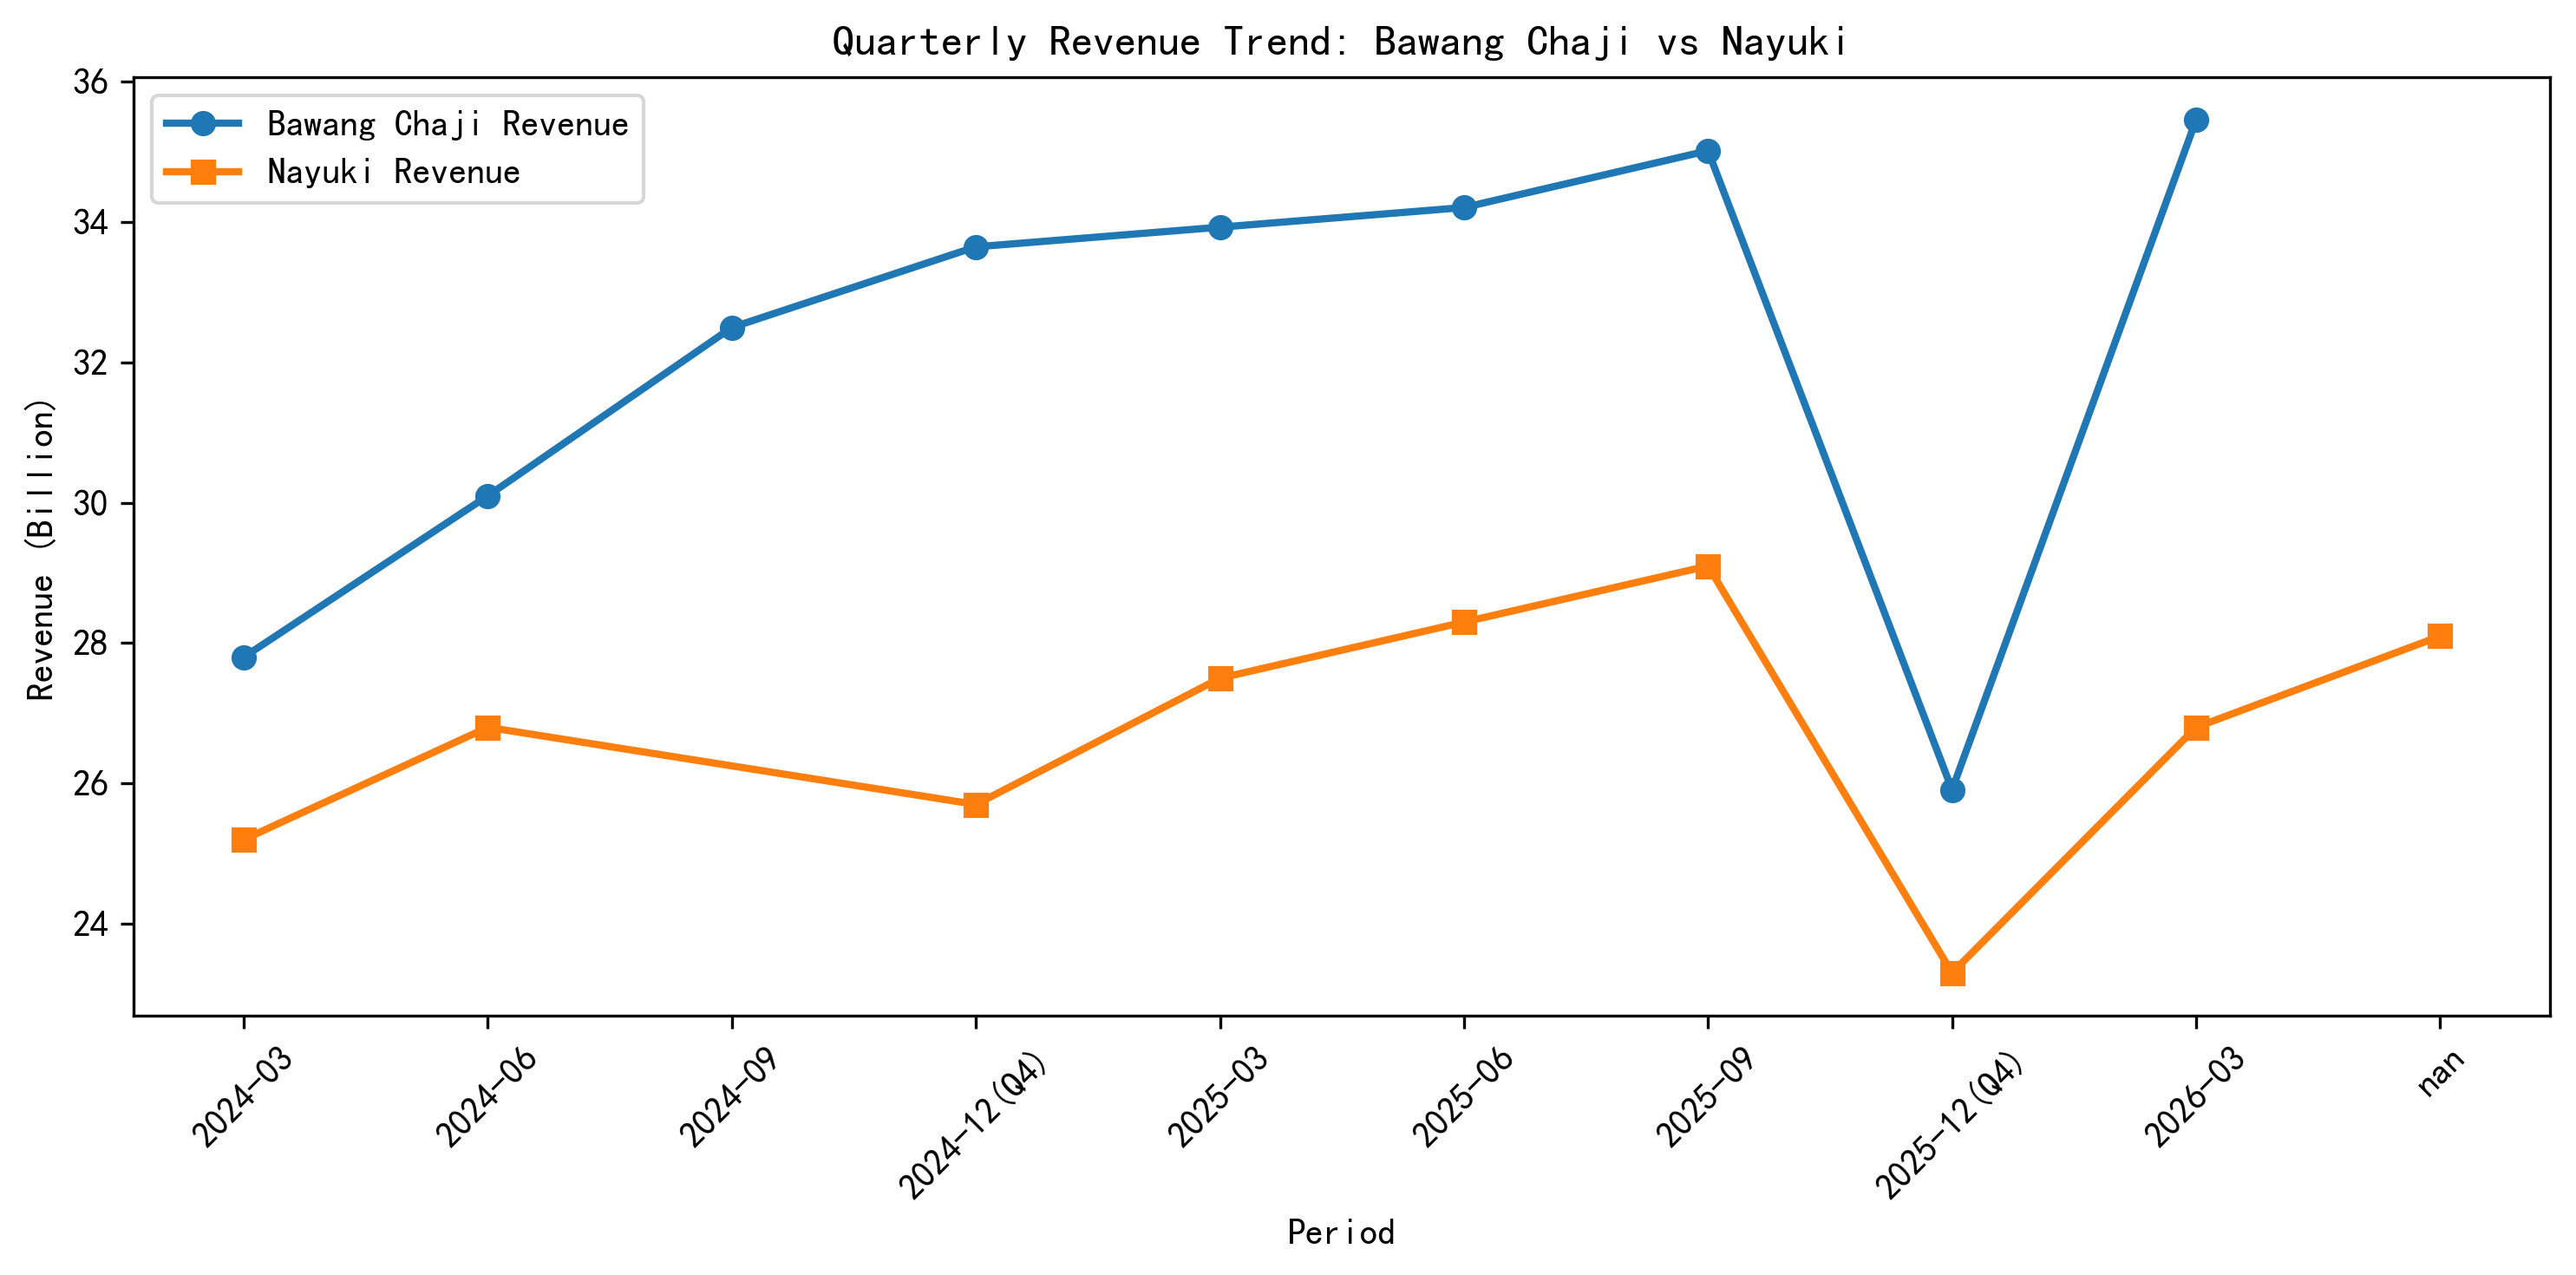

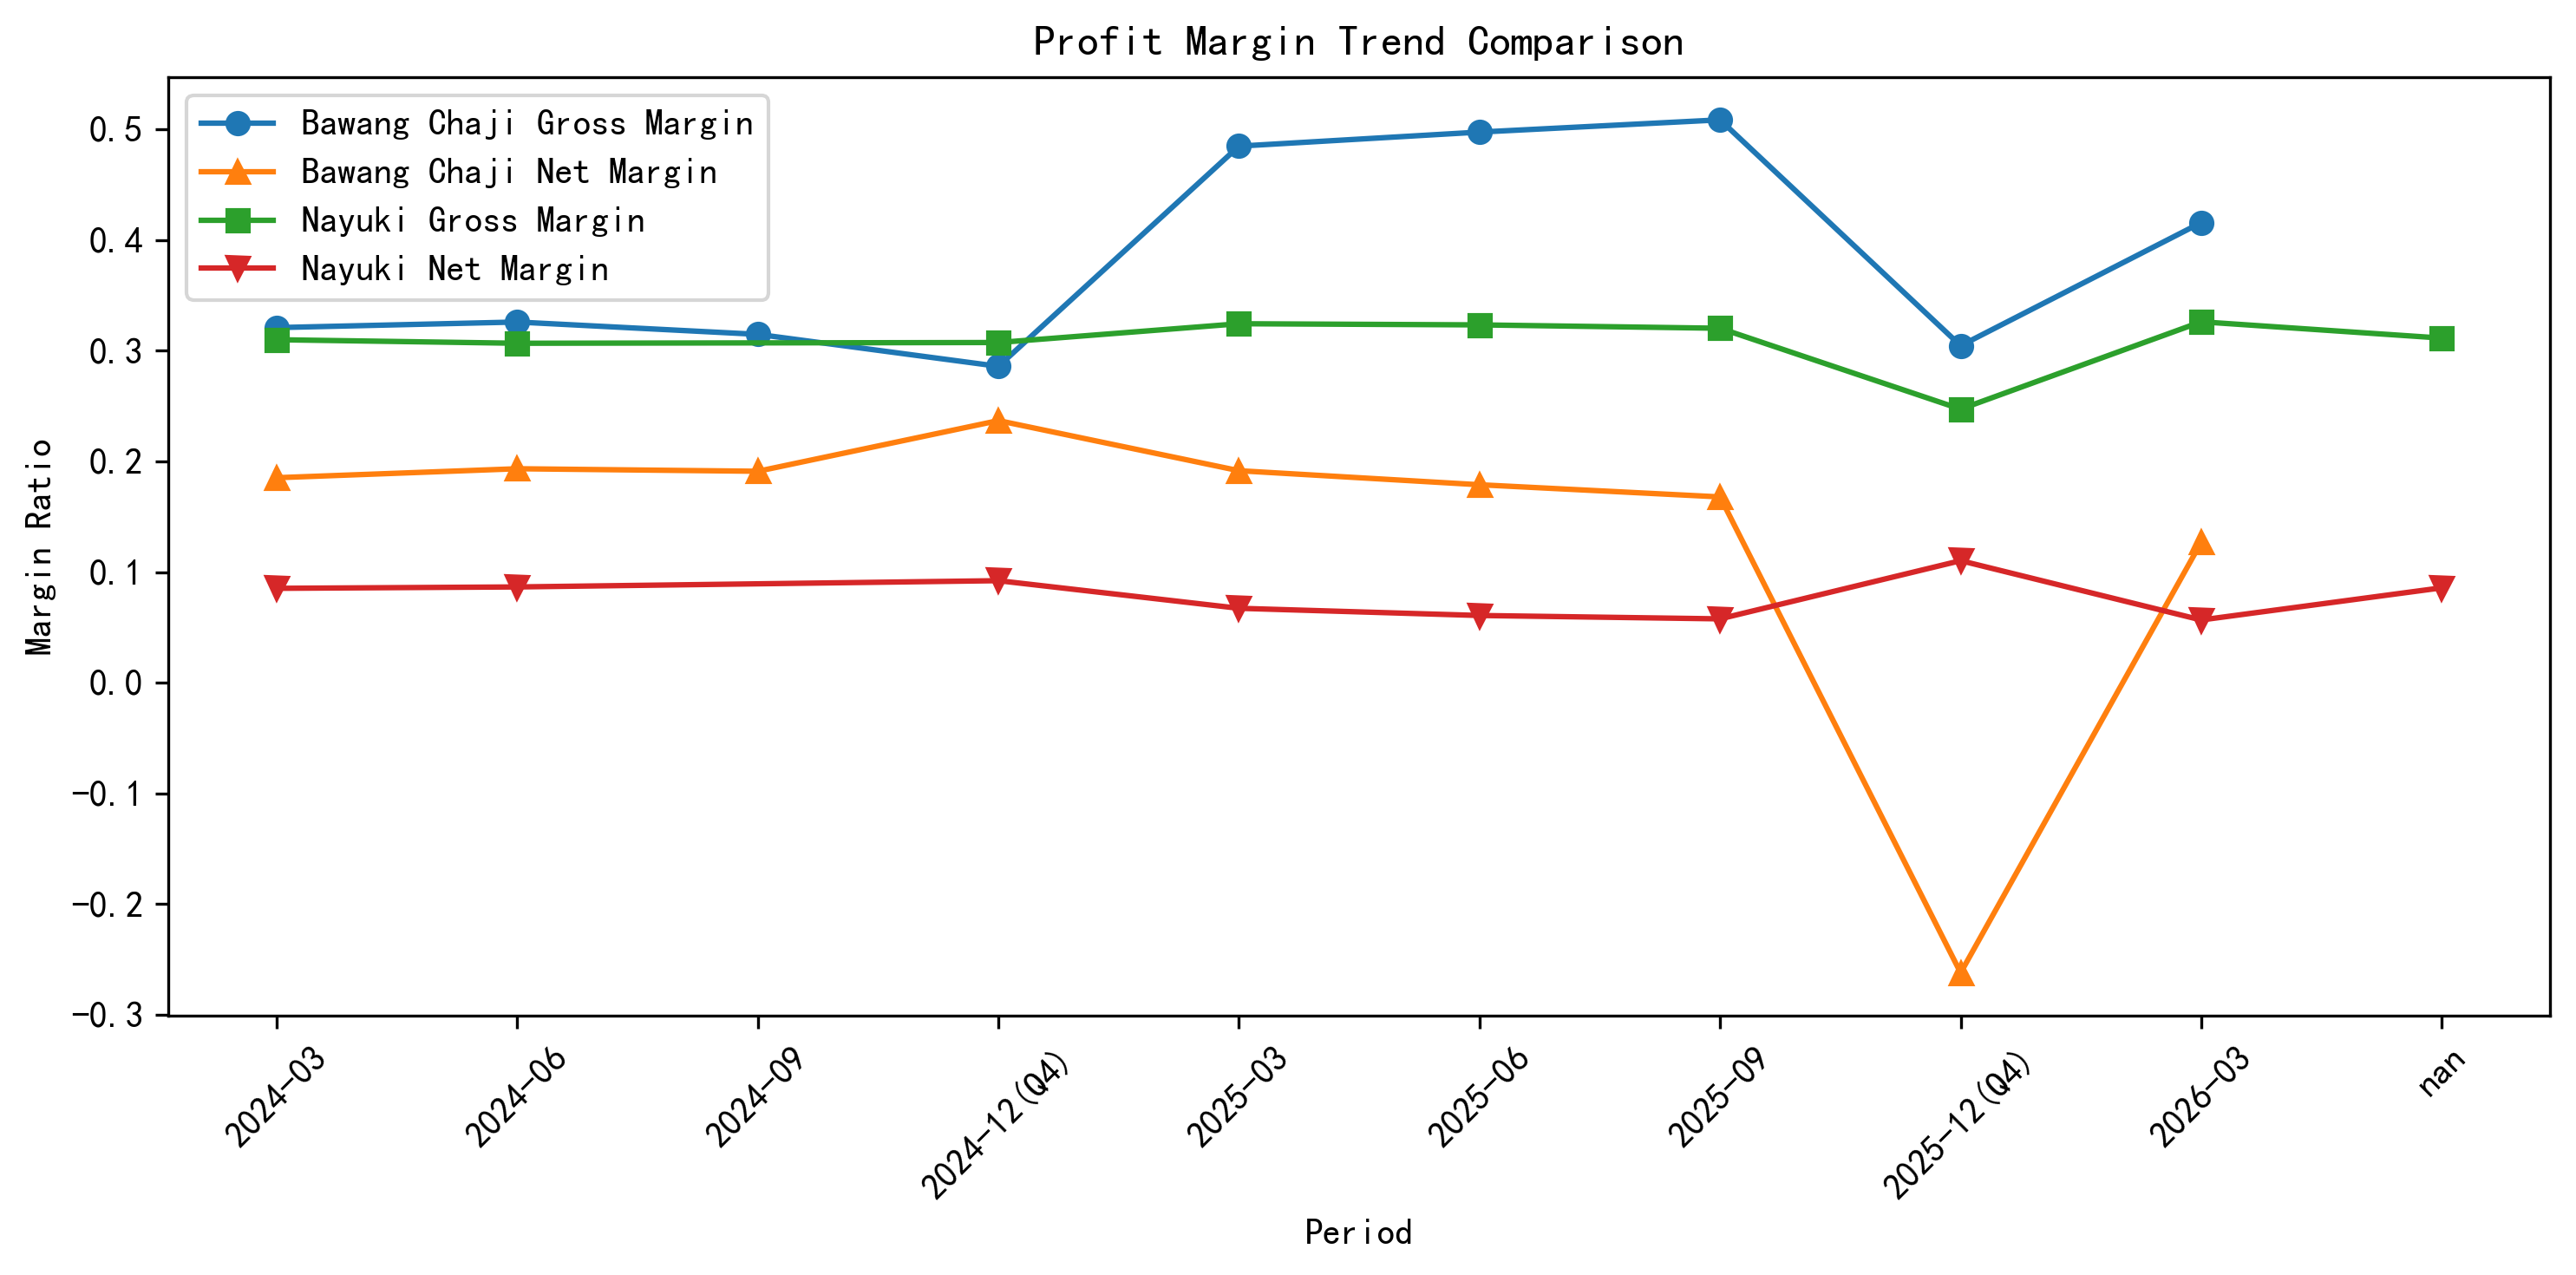

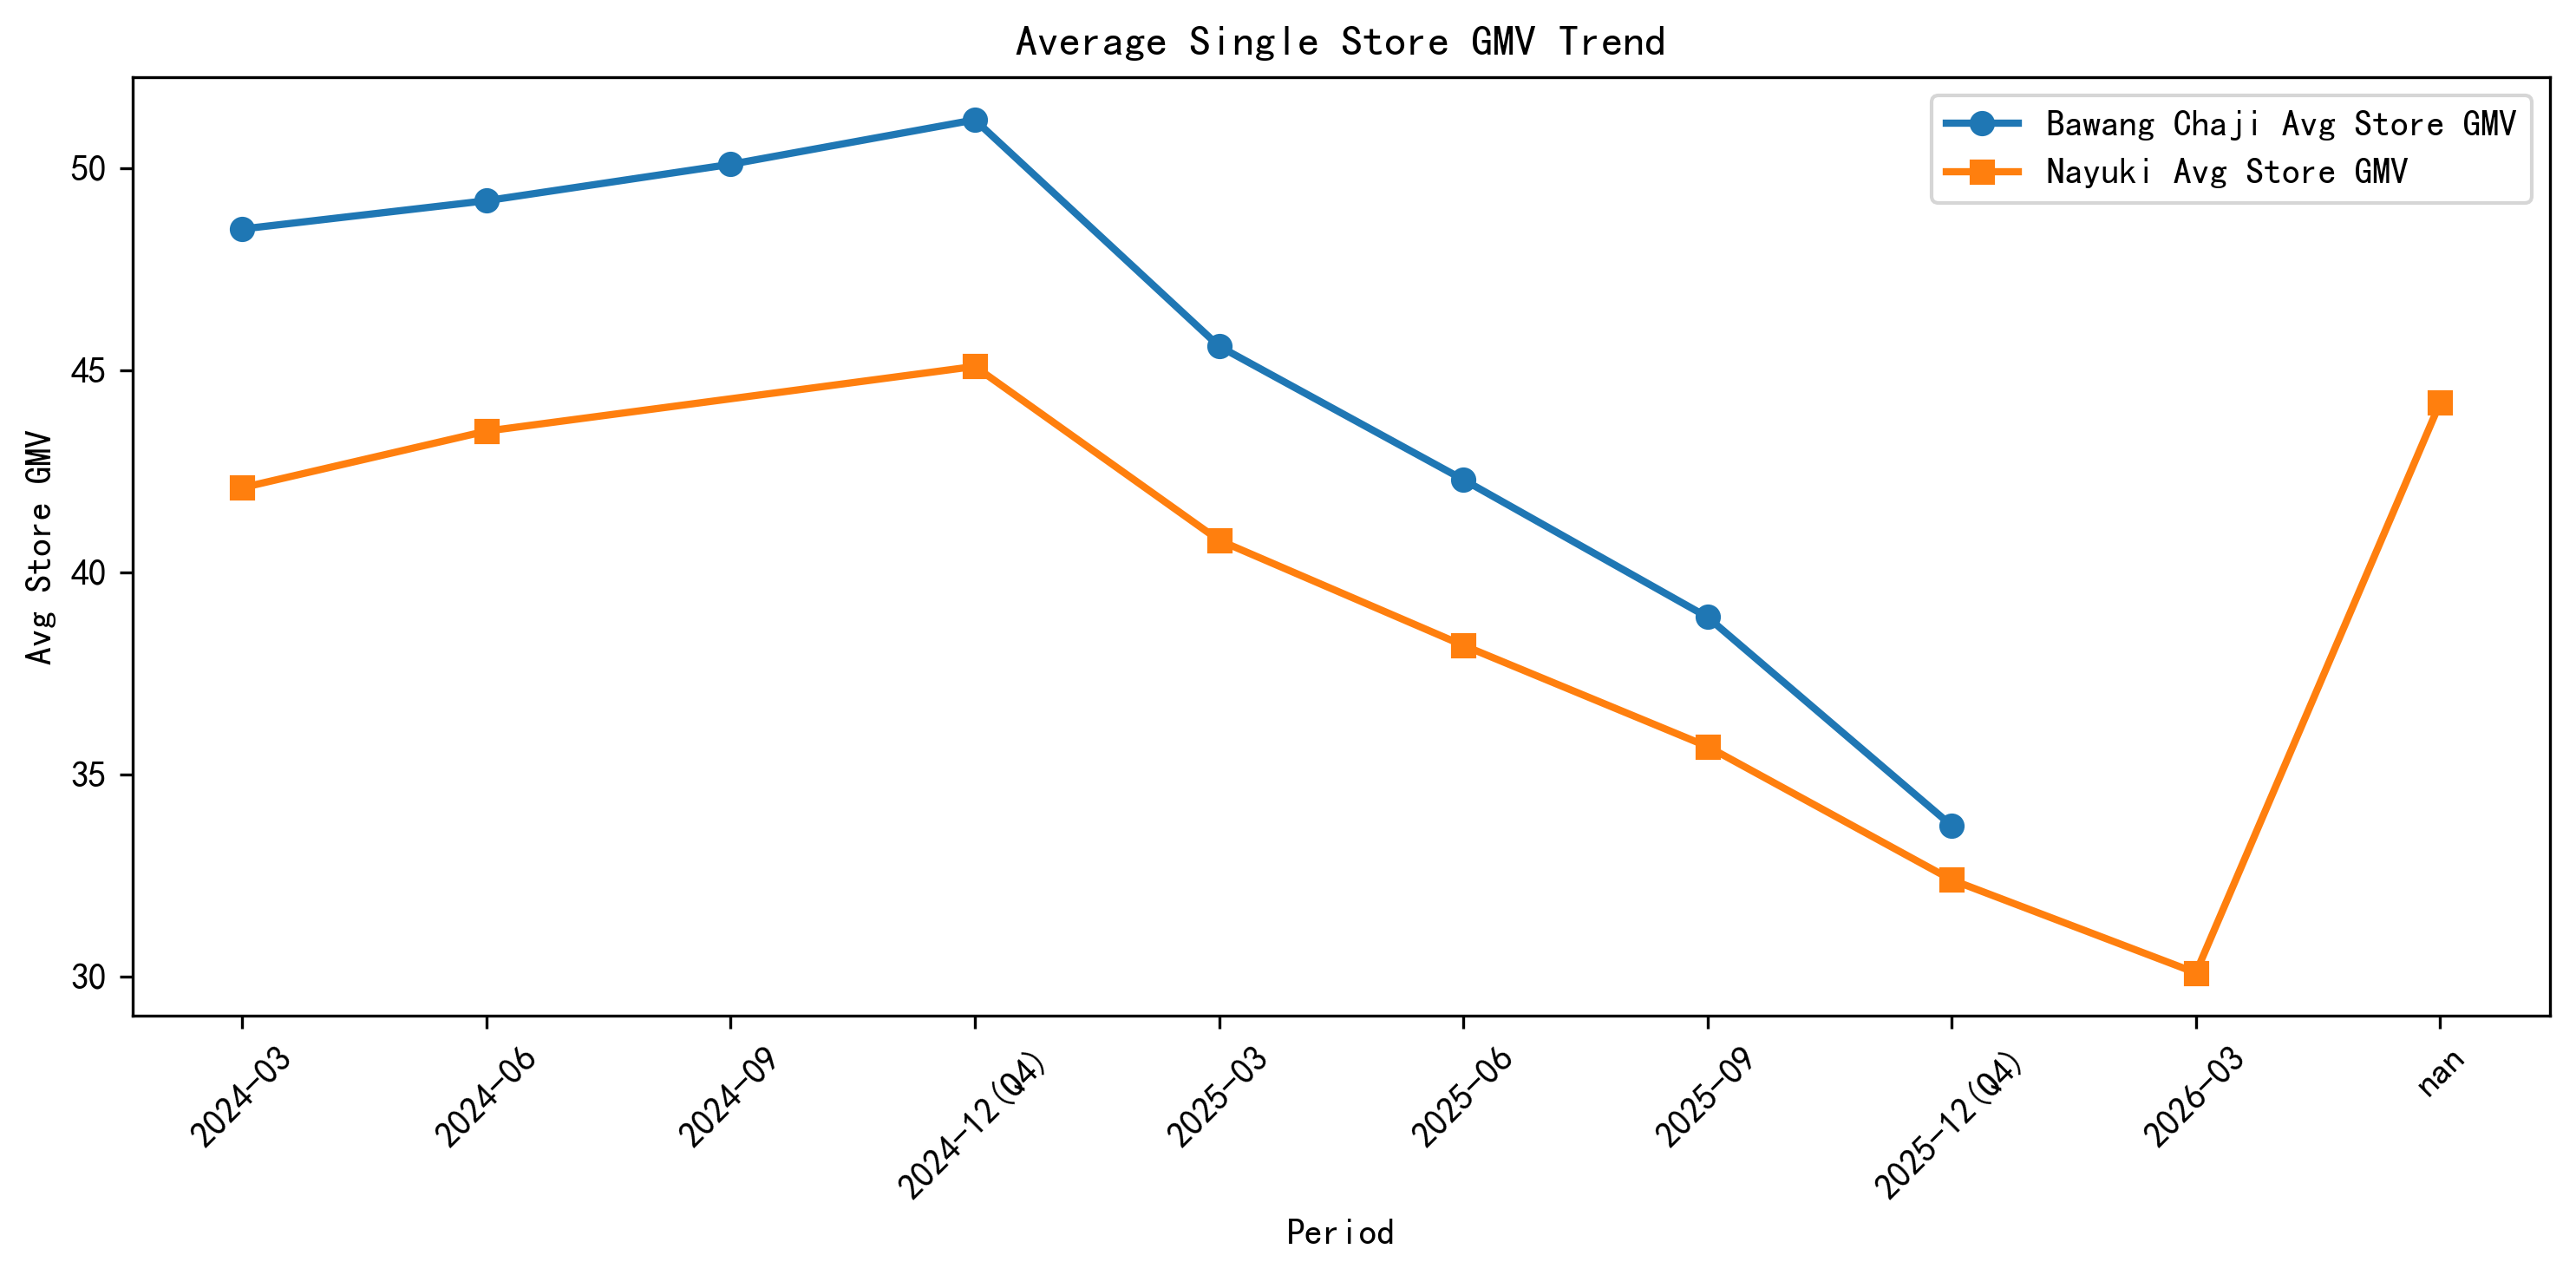

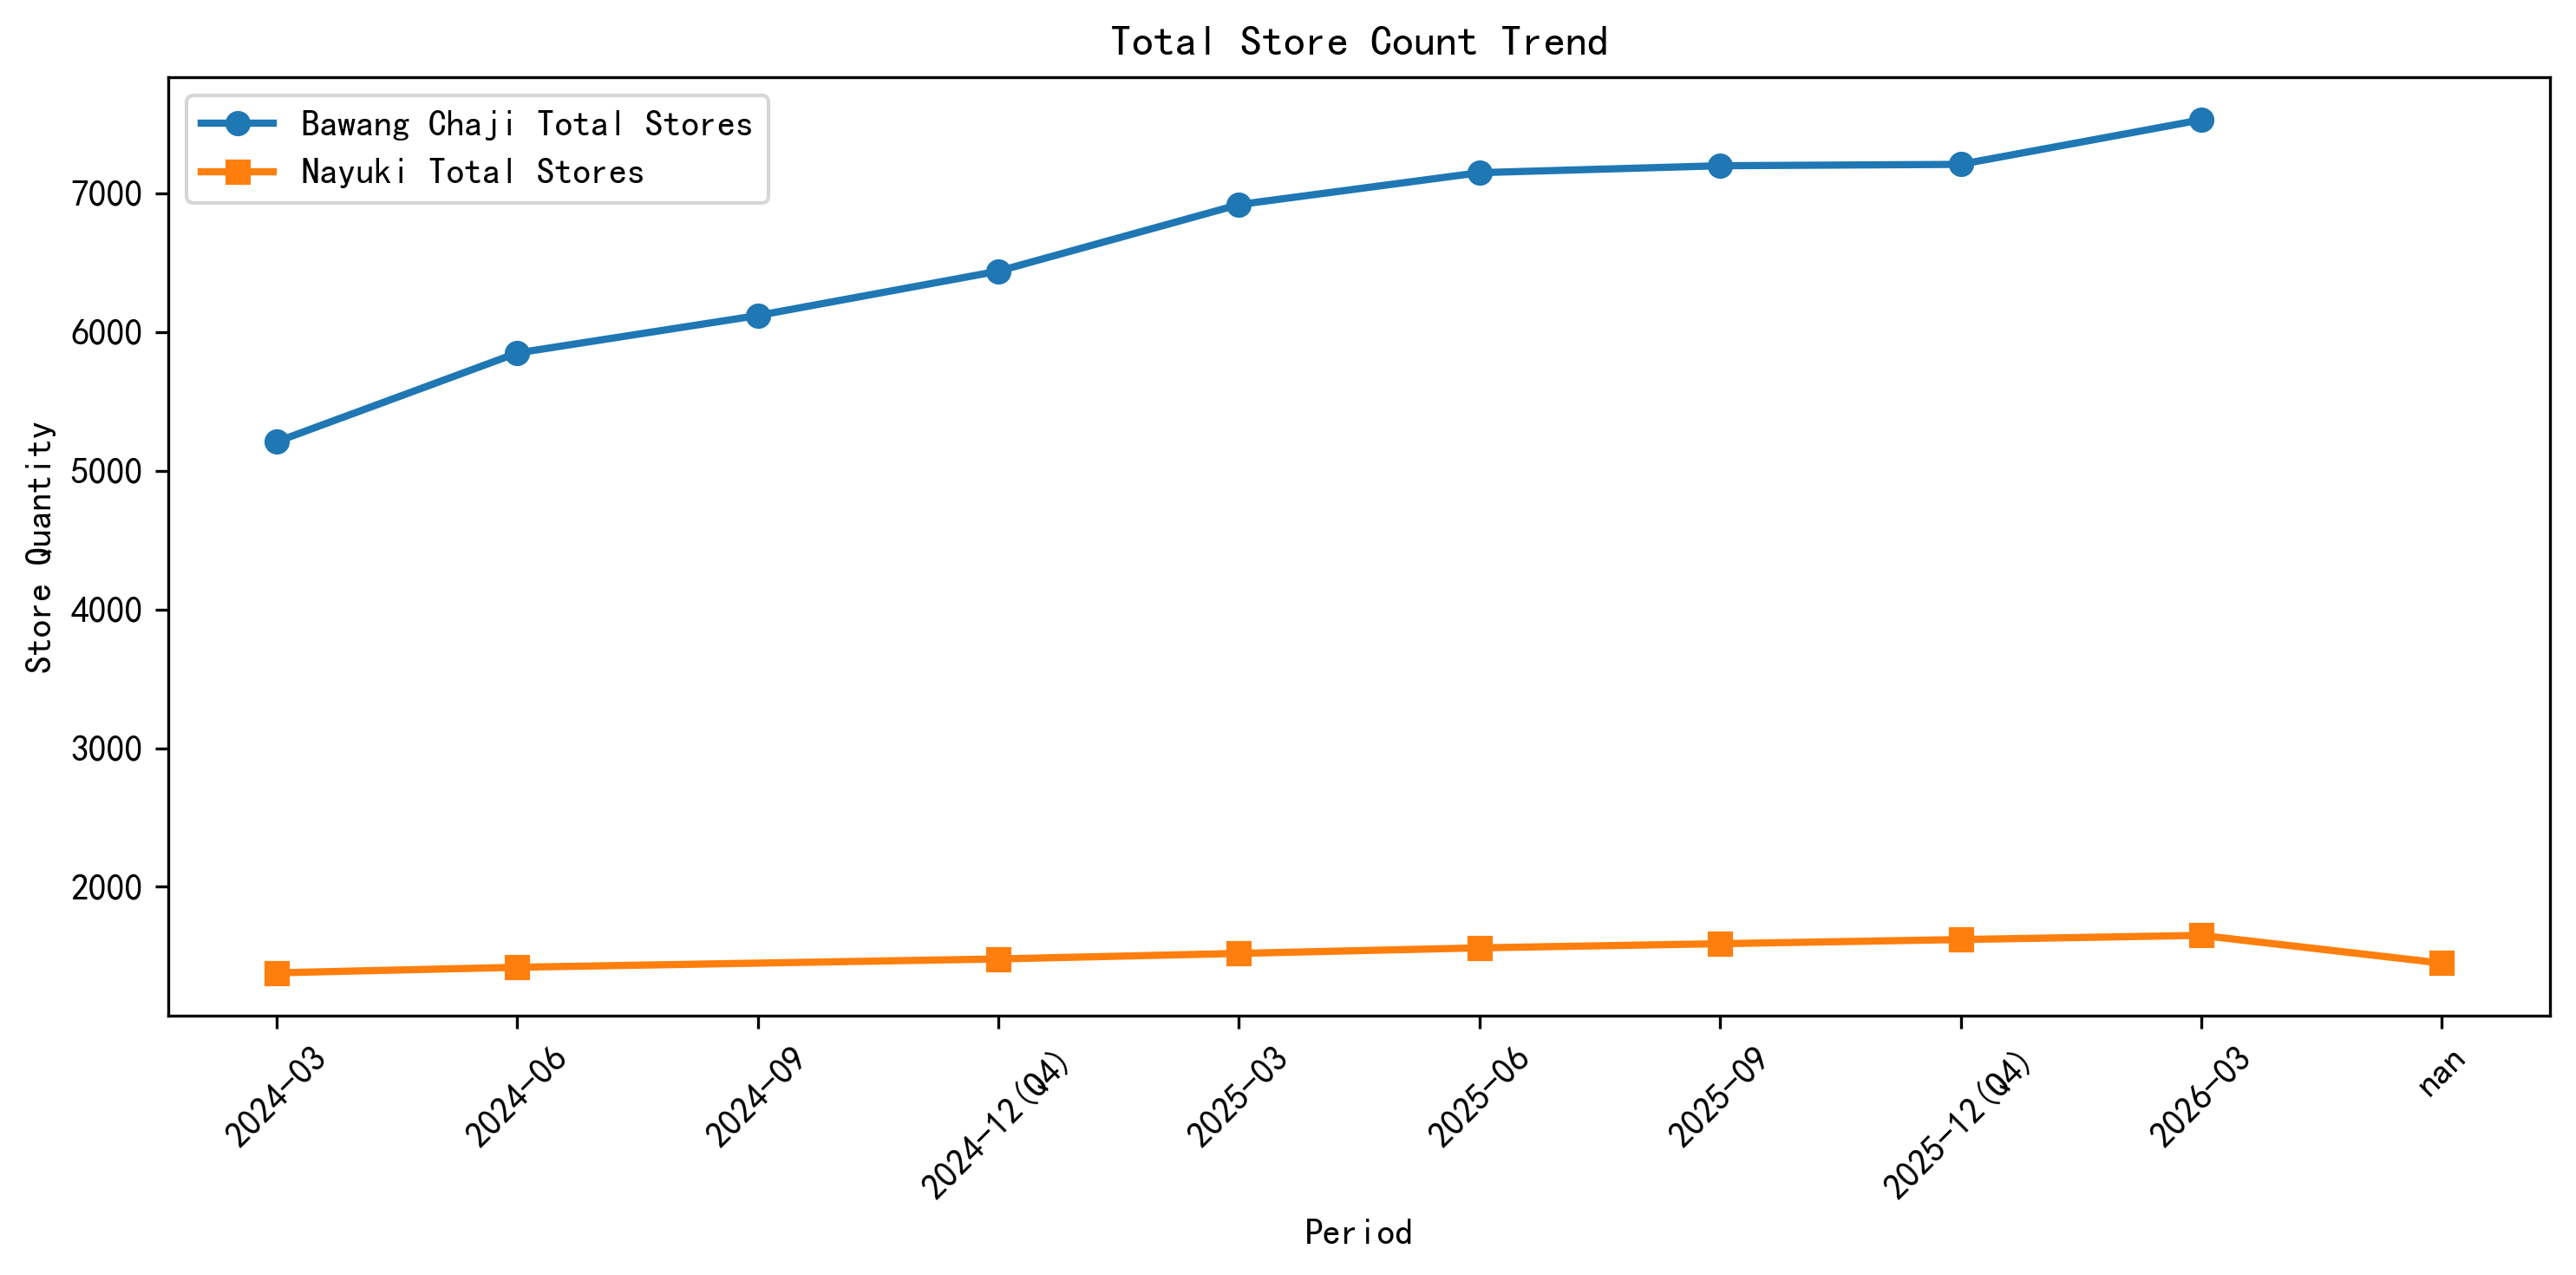

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# 设置中文，防止乱码
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams['axes.unicode_minus'] = False

# 读取清洗后数据
df_cha_clean = pd.read_csv("cha_data_processed.csv")
df_naixue_clean = pd.read_csv("naixue_data_processed.csv")

# =========关键修复：强制period转为字符串，处理空值，替换特殊连字符=========
df_cha_clean["period"] = df_cha_clean["period"].astype(str).str.replace("‑", "-")
df_naixue_clean["period"] = df_naixue_clean["period"].astype(str).str.replace("‑", "-")

# ------------图1：季度营收对比趋势------------
plt.figure(figsize=(10,5),dpi=300)
plt.plot(df_cha_clean["period"],df_cha_clean["total_revenue"],marker='o',linewidth=2,label="Bawang Chaji Revenue")
plt.plot(df_naixue_clean["period"],df_naixue_clean["total_revenue"],marker='s',linewidth=2,label="Nayuki Revenue")
plt.title("Quarterly Revenue Trend: Bawang Chaji vs Nayuki")
plt.xlabel("Period")
plt.ylabel("Revenue (Billion)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("revenue_trend.png")
plt.show()

# ------------图2：毛利率 & 净利率对比------------
plt.figure(figsize=(10,5),dpi=300)
plt.plot(df_cha_clean["period"],df_cha_clean["gross_margin"],marker='o',label="Bawang Chaji Gross Margin")
plt.plot(df_cha_clean["period"],df_cha_clean["net_margin"],marker='^',label="Bawang Chaji Net Margin")
plt.plot(df_naixue_clean["period"],df_naixue_clean["gross_margin"],marker='s',label="Nayuki Gross Margin")
plt.plot(df_naixue_clean["period"],df_naixue_clean["net_margin"],marker='v',label="Nayuki Net Margin")
plt.title("Profit Margin Trend Comparison")
plt.xlabel("Period")
plt.ylabel("Margin Ratio")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("margin_trend.png")
plt.show()

# ------------图3：单店GMV趋势（核心业务洞察）------------
plt.figure(figsize=(10,5),dpi=300)
plt.plot(df_cha_clean["period"],df_cha_clean["avg_store_gmv"],marker='o',linewidth=2,label="Bawang Chaji Avg Store GMV")
plt.plot(df_naixue_clean["period"],df_naixue_clean["avg_store_gmv"],marker='s',linewidth=2,label="Nayuki Avg Store GMV")
plt.title("Average Single Store GMV Trend")
plt.xlabel("Period")
plt.ylabel("Avg Store GMV")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("store_gmv_trend.png")
plt.show()

# ------------图4：门店总数扩张趋势------------
plt.figure(figsize=(10,5),dpi=300)
plt.plot(df_cha_clean["period"],df_cha_clean["store_total"],marker='o',linewidth=2,label="Bawang Chaji Total Stores")
plt.plot(df_naixue_clean["period"],df_naixue_clean["store_total"],marker='s',linewidth=2,label="Nayuki Total Stores")
plt.title("Total Store Count Trend")
plt.xlabel("Period")
plt.ylabel("Store Quantity")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("store_count_trend.png")
plt.show()


# Key Business Findings
1. Store expansion vs unit economics：Bawang Chaji rapidly expanded store network, but average single-store GMV kept declining, showing store dilution effect. Rapid franchise expansion intensified intra-brand competition and pressured single-store profitability.
2. Profitability divergence: Both firms faced "revenue growth without profit growth", but with different underlying drivers. Nayuki’s pressure came from high rental and labor costs under direct-operating model; Bawang Chaji’s margin pressure was from franchise ecosystem competition.
3. GMV-Revenue conversion gap: Bawang Chaji adopts franchise model. Its GMV represents full-store sales, while recognized revenue only includes material supply and franchise fees, resulting in much lower conversion ratio. Nayuki’s direct-store model makes GMV close to reported revenue.

## Project Limitations
1. Limited dataset: Only covers several quarters of two listed new-tea firms, cannot represent the whole new tea industry.
2. Missing data: Partial franchise/direct store indicators after Q1 2025 are unavailable due to limited public disclosure.
3. Simplified analysis: Macroeconomic factors, promotion pricing and consumer traffic are not quantitatively modeled; this is descriptive analysis rather than causal inference.
